# Modelo de clasificación usando `DecisionTreeClassifier`

**Autor:** Jazna Meza Hidalgo

**Correo Electrónico:** ymeza@ubiobio.cl

**Fecha de Creación:** Octubre de 2026  
**Versión:** 1.0  

---

## Descripción

Este notebook ofrece la explicación de la creación de un modelo de clasificación usando `DecisionTreeClassifier`.

Aplica `GridSearchCV` para la búsqueda de hiperparámetros tratando de conseguir un modelo optimizado


---

## Requisitos de Software

Este notebook fue desarrollado con Python 3.12. A continuación se listan las bibliotecas necesarias:

- pandas (>=1.1.0)
- matplotlib (3.7.1)
- numpy (2.0.2)


Para verificar la versión instalada ejecutar usando el siguiente comando, usando la librería de la cual quieres saber la versión:

```python
import pandas as pd
print(pd.__version__)
````

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    auc,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score
)
from sklearn.model_selection import GridSearchCV, train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [ ]:
!wget https://raw.githubusercontent.com/JaznaLaProfe/InteligenciaArtificial/master/data/churn_client_telco.csv

--2026-10-30 15:49:08--  https://raw.githubusercontent.com/JaznaLaProfe/InteligenciaArtificial/master/data/churn_client_telco.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1645132 (1.6M) [text/plain]
Saving to: ‘churn_client_telco.csv’

churn_client_telco. 100%[===================>]   1.57M  --.-KB/s    in 0.04s   

2026-10-30 15:49:09 (41.5 MB/s) - ‘churn_client_telco.csv’ saved [1645132/1645132]



In [ ]:
data = pd.read_csv("churn_client_telco.csv")
data.head()

,Unnamed: 0,Antiguedad_Meses,Monto_Mensual,Llamadas_Soporte,Pago_Automatico,Churn
0,0,35,53.178013,3,1,1
1,1,41,47.529905,1,1,0
2,2,25,69.518305,3,1,1
3,3,28,50.827143,2,0,1
4,4,70,101.612840,6,1,1


In [ ]:
# Elimina la(s) columnas sin aporte para el modelo
data.drop(["Unnamed: 0"], axis=1, inplace=True)

In [ ]:
target = "Churn"
X = data.drop(target, axis=1)
y = data[target]

In [ ]:
# Revisa la distribución de la variable objetivo
y.value_counts(normalize=True)

,proportion
Churn,
1,0.6261
0,0.3739


In [ ]:
y.value_counts()

,count
Churn,
1,31305
0,18695


In [ ]:
target_names = ["Permanece", "Renuncia"]

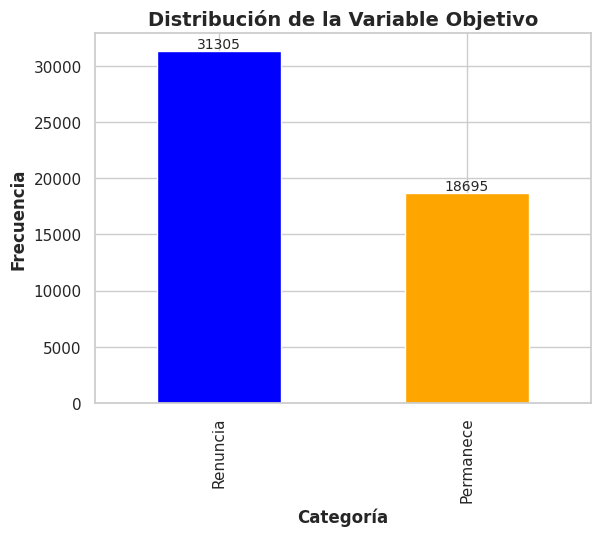

In [ ]:
# Gráfica de la distribución de la variable objetivo
y.value_counts().plot(kind="bar", color=["blue", "orange"])
plt.title("Distribución de la Variable Objetivo", fontsize=14, fontweight="bold")
plt.xlabel("Categoría", fontsize=12, fontweight="bold")
plt.ylabel("Frecuencia", fontsize=12, fontweight="bold")
# Agregar etiquetas a los valores del eje X
for i, value in enumerate(y.value_counts()):
    plt.text(i, value, str(value), ha="center", va="bottom", fontsize=10)
# Agrega la etiqueta de cada clase
plt.xticks(ticks=[0, 1], labels=["Renuncia", "Permanece"])
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=29, stratify=y
)

# `DecisionTreeClassifier`

## Modelo línea base (baseline)

Árbol por defecto (suele sobreajustar / overfitting al no tener límite de profundidad)

In [ ]:
baseline_tree = DecisionTreeClassifier(random_state=29)
baseline_tree.fit(X_train, y_train)

# Predicciones
y_pred_base = baseline_tree.predict(X_test)
y_proba_base = baseline_tree.predict_proba(X_test)[:, 1]

In [ ]:
# Comprueba la existencia de overfitting
print(f"ROC-AUC Línea Base: {roc_auc_score(y_test, y_proba_base):.4f}")
print("="*100)
print(f"F1-score línea base en train: {f1_score(y_train, baseline_tree.predict(X_train)):.4f}")
print(f"F1-score línea base en test: {f1_score(y_test, y_pred_base):.4f}")

ROC-AUC Línea Base: 0.9915
F1-score línea base en train: 1.0000
F1-score línea base en test: 0.9939


## Optimización

In [ ]:
# Define el espacio de búsqueda de hiperparámetros
param_grid = {
    "criterion": ["gini", "entropy"],  # Criterios de pureza
    "max_depth": [3, 4, 5, 6, 8],  # Control de profundidad para evitar overfitting
    "min_samples_split": [5, 10, 20],  # Mínimo de muestras para dividir un nodo
    "min_samples_leaf": [2, 5, 10],  # Mínimo de muestras en hojas
    "class_weight": [None, "balanced"],  # Peso de las clases
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=29),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=29),  # Validacion cruzada de 5 pliegues
    scoring="roc_auc",  # Optimizado para ROC-AUC
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)
best_tree = grid_search.best_estimator_

# Predicciones del modelo optimizado
y_pred_opt = best_tree.predict(X_test)
y_proba_opt = best_tree.predict_proba(X_test)[:, 1]

In [ ]:
y_proba_opt[(y_proba_opt < 1) & (y_proba_opt > 0)]

array([0.93722427, 0.10301354, 0.56898445, ..., 0.3739    , 0.14005844,
       0.73843045])

In [ ]:
best_tree.predict_proba(X_test)[-5:].round(3)

array([[1.   , 0.   ],
       [0.262, 0.738],
       [0.   , 1.   ],
       [0.   , 1.   ],
       [1.   , 0.   ]])

In [ ]:
y_pred_opt[-5:]

array([0, 1, 1, 1, 0])

## Comparación y evaluación de resultados

In [ ]:
auc_base = roc_auc_score(y_test, y_proba_base)
auc_opt = roc_auc_score(y_test, y_proba_opt)

print("--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---")
print(grid_search.best_params_)
print("\n" + "=" * 50)
print(f"ROC-AUC Línea Base: {auc_base:.4f}")
print(f"ROC-AUC Optimizado: {auc_opt:.4f}")
print("=" * 50)

print("\n--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---")
print(classification_report(y_test, y_pred_base, target_names=target_names))

print("--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---")
print(classification_report(y_test, y_pred_opt, target_names=target_names))


--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 10, 'min_samples_split': 5}

ROC-AUC Línea Base: 0.9915
ROC-AUC Optimizado: 0.9944

--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---
              precision    recall  f1-score   support

   Permanece       0.99      0.99      0.99      3739
    Renuncia       0.99      0.99      0.99      6261

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---
              precision    recall  f1-score   support

   Permanece       0.95      0.97      0.96      3739
    Renuncia       0.98      0.97      0.98      6261

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [ ]:
def view_matrix(y_test: np.array, y_pred: np.array, model_desc: str="Linea Base"):
  """
  Muestra la matriz de confusión como mapa de calor

  Parameters
  ----------
  y_test : np.array
    Valores reales
  y_pred : np.array
    Predicciones del modelo
  model_desc : str
    Descripción del modelo
  """
  #
  plt.figure(figsize=(4, 3))
  sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    cbar=False,
  )
  plt.xlabel("Predicción", fontsize=12, fontweight="bold")
  plt.ylabel("Valor Real", fontsize=12, fontweight="bold")
  plt.title(f"Matriz de Confusión ({model_desc})", fontsize=14, fontweight="bold")
  plt.show()

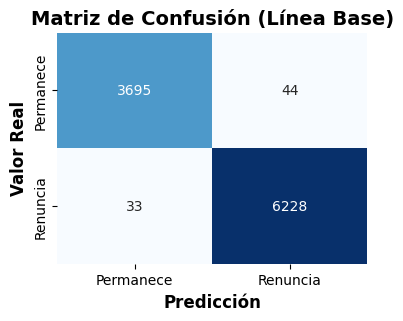

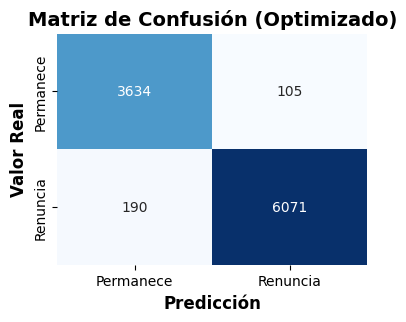

In [ ]:
view_matrix(y_test, y_pred_base, "Línea Base")
view_matrix(y_test, y_pred_opt, "Optimizado")

## Curva ROC-AUC

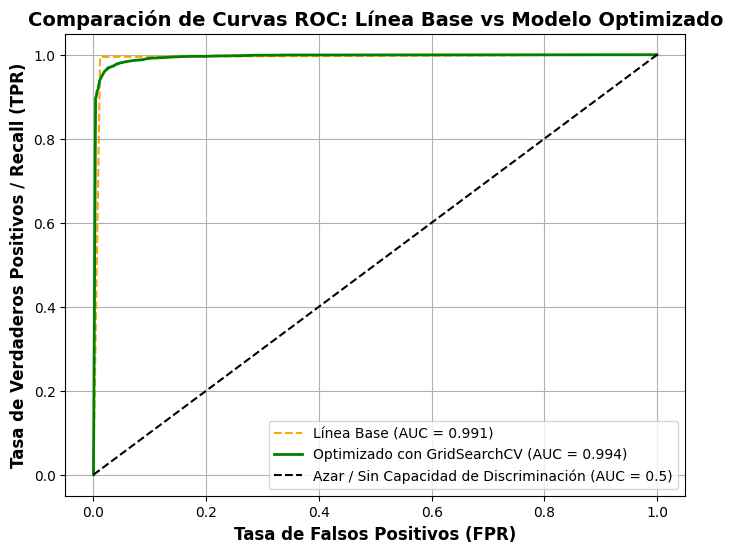

In [ ]:
fpr_base, tpr_base, _ = roc_curve(y_test, y_proba_base)
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_proba_opt)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_base,
    tpr_base,
    label=f"Línea Base (AUC = {auc_base:.3f})",
    color="orange",
    linestyle="--",
)
plt.plot(
    fpr_opt,
    tpr_opt,
    label=f"Optimizado con GridSearchCV (AUC = {auc_opt:.3f})",
    color="green",
    linewidth=2,
)
plt.plot([0, 1], [0, 1], "k--", label="Azar / Sin Capacidad de Discriminación (AUC = 0.5)")

plt.xlabel("Tasa de Falsos Positivos (FPR)", fontsize=12, fontweight="bold")
plt.ylabel("Tasa de Verdaderos Positivos / Recall (TPR)", fontsize=12, fontweight="bold")
plt.title("Comparación de Curvas ROC: Línea Base vs Modelo Optimizado", fontsize=14, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

## Visualización del árbol de decisión optimizado

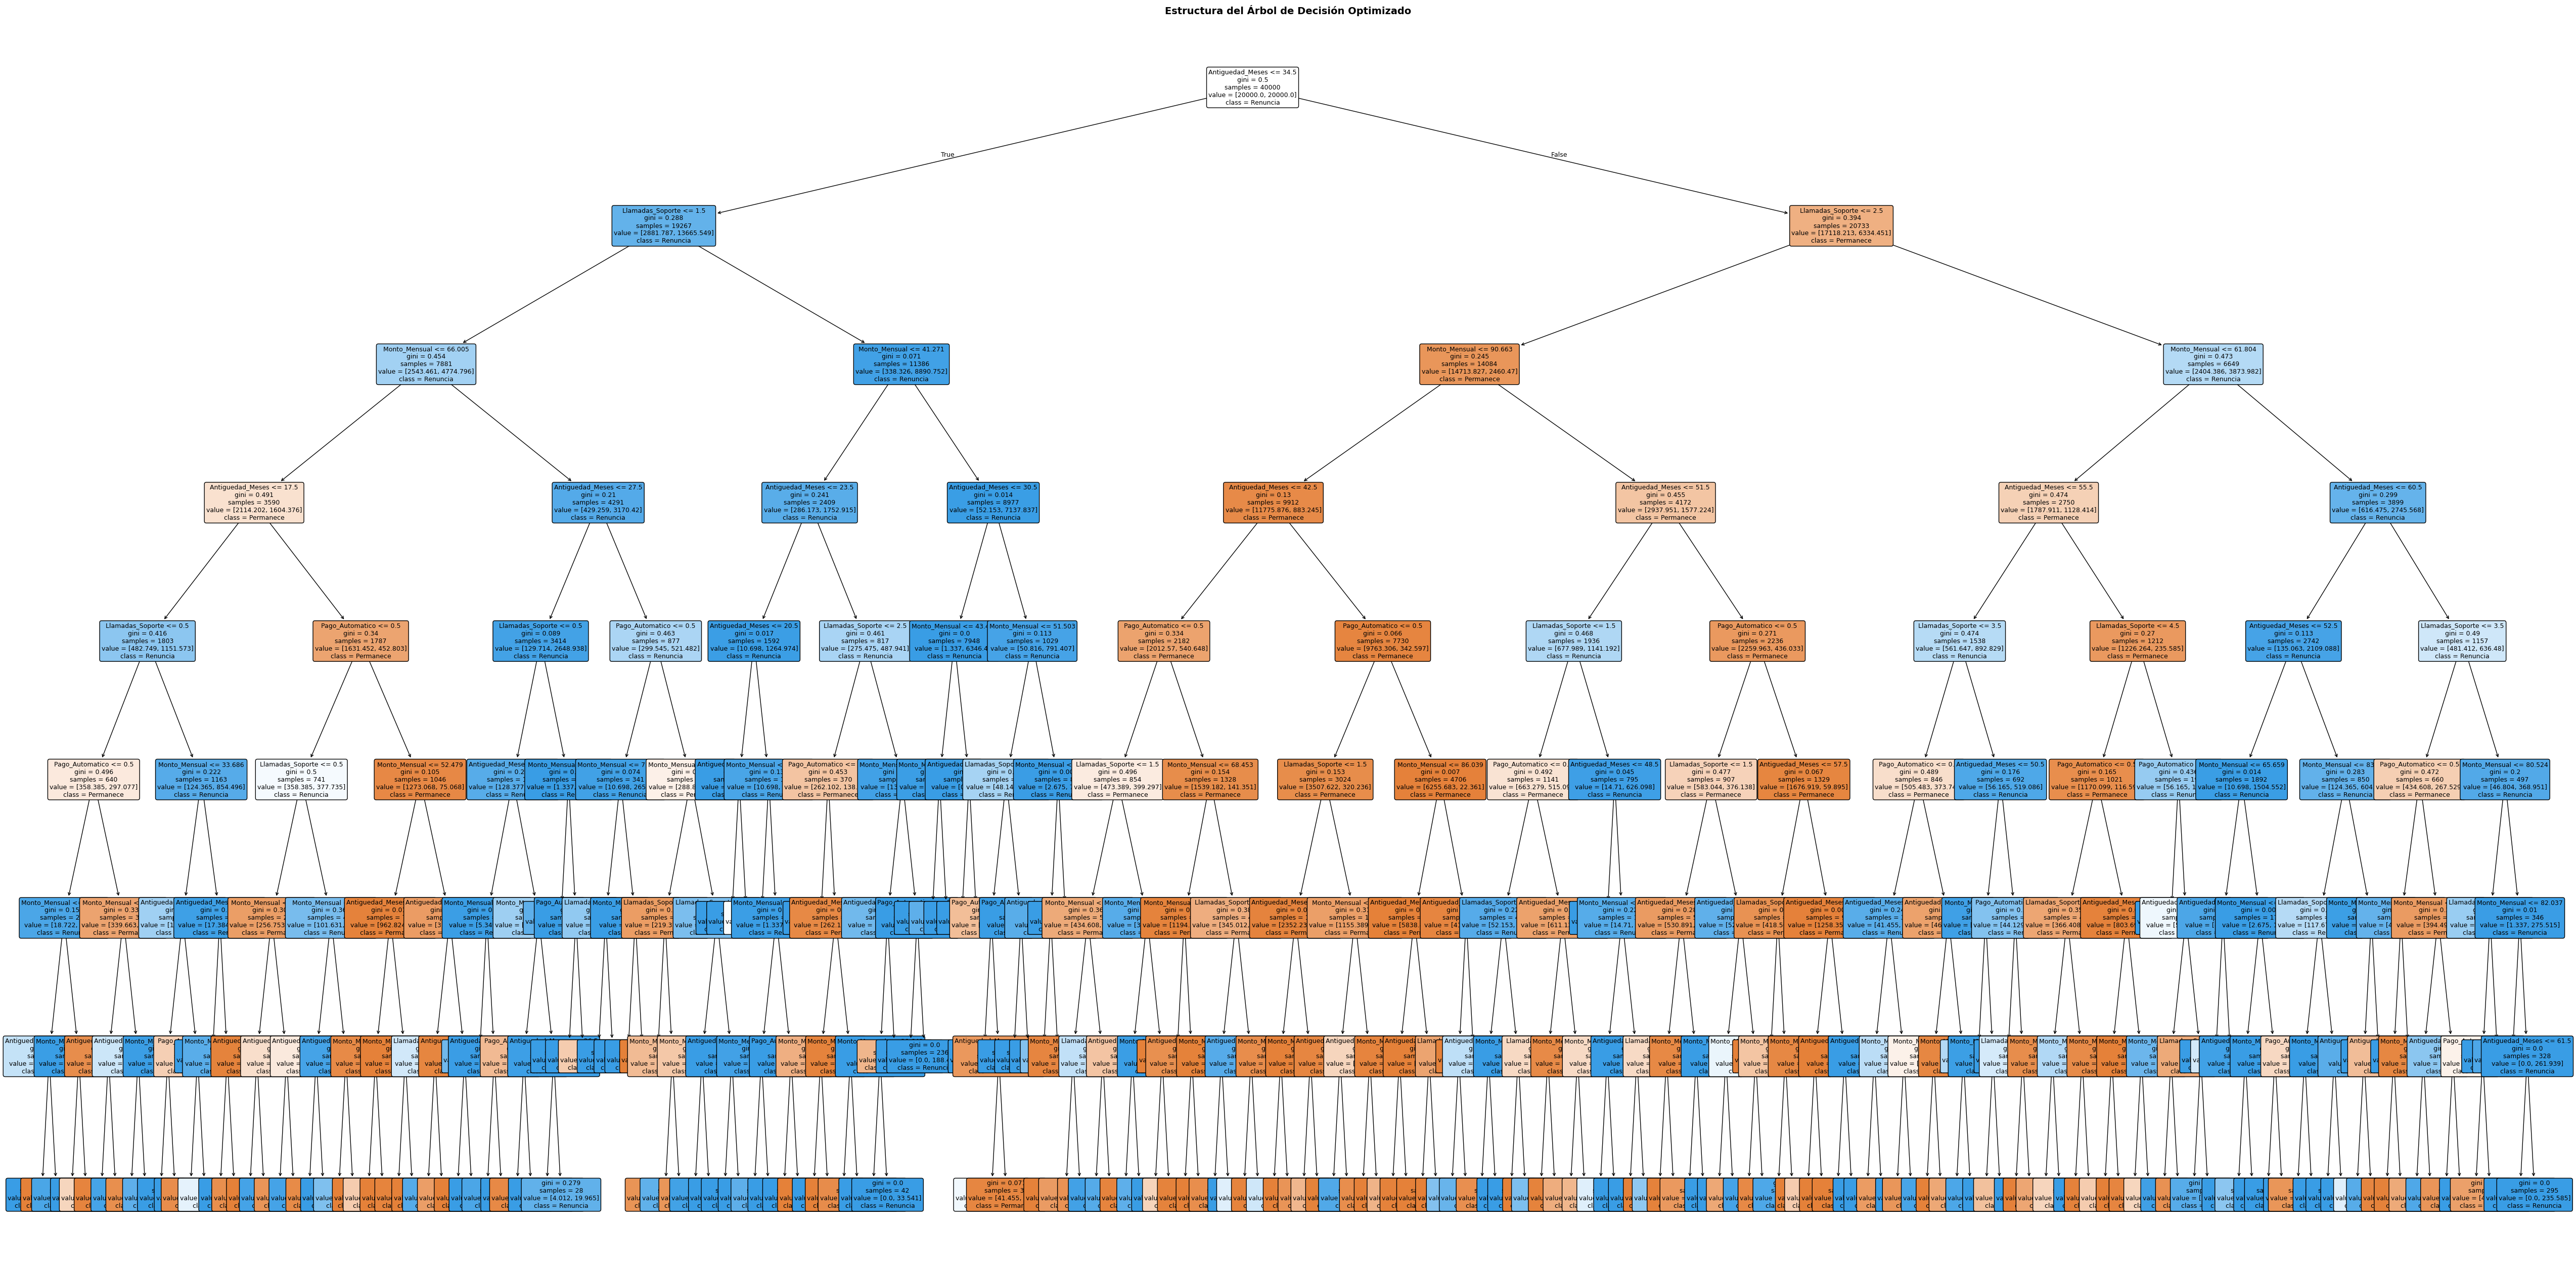

In [ ]:
plt.figure(figsize=(64, 32))
plot_tree(
    best_tree,
    feature_names=X.columns,
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Estructura del Árbol de Decisión Optimizado", fontsize=14, fontweight="bold")
plt.show()

In [ ]:
# Extracción de la importancia relativa de cada variable para el negocio
importances = best_tree.feature_importances_
feature_imp_df = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False)

display(feature_imp_df)

,Variable,Importancia
0,Antiguedad_Meses,0.468365
2,Llamadas_Soporte,0.269704
1,Monto_Mensual,0.167778
3,Pago_Automatico,0.094153


In [ ]:
np.sum(importances)

np.float64(0.9999999999999999)

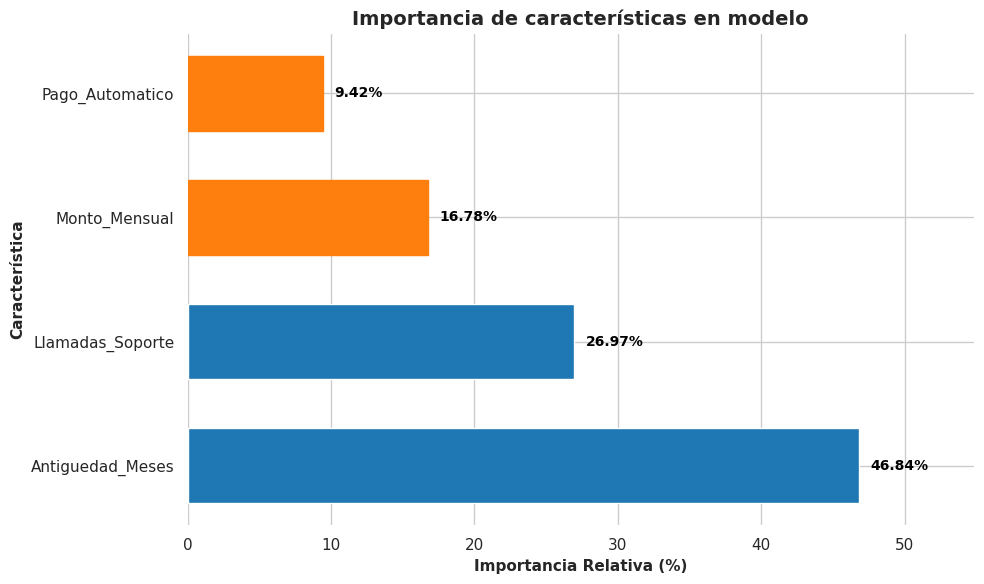

In [ ]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 6))

# Define colors
primary_color = '#1f77b4'
highlight_color =  '#ff7f0e'
text_color = '#000000'

bars = ax.barh(feature_imp_df['Variable'], feature_imp_df['Importancia']*100, color=primary_color, height=0.6)

# Highlight top 2 features
bars[-1].set_color(highlight_color)
bars[-2].set_color(highlight_color)

# Annotate bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.8, bar.get_y() + bar.get_height()/2, f"{width:.2f}%",
            va='center', ha='left', fontsize=10, fontweight='bold', color=text_color)

ax.set_title("Importancia de características en modelo", fontsize=14, fontweight='bold')

ax.set_xlabel("Importancia Relativa (%)", fontsize=11, fontweight='bold')
ax.set_xlim(0, max(feature_imp_df['Importancia'])*100 + 8)

sns.despine(left=True, bottom=True)
ax.set_ylabel("Característica", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

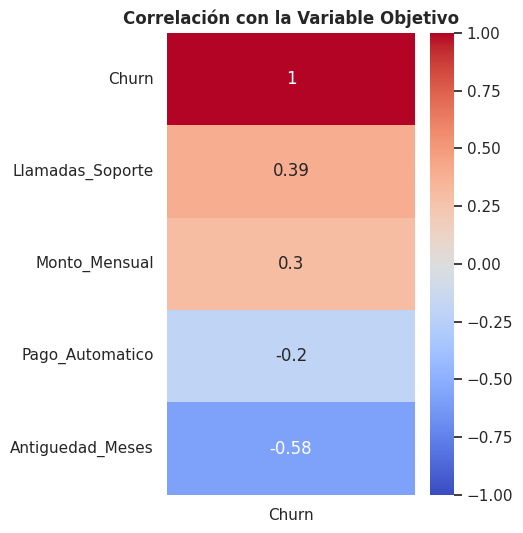

In [ ]:
# Calcula la correlación de las variables con la variable objetivo
correlation_with_target = data.corr()[[target]].sort_values(by=target, ascending=False)
# Muestra las correlaciones como un mapa de correlación
plt.figure(figsize=(4, 6))
sns.heatmap(
    correlation_with_target,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlación con la Variable Objetivo", fontsize=12, fontweight="bold")
plt.show()